# フェーズ1：決定点まわりの判断（D1〜D7）の根拠

`reports/phase1_decisions.md` の D1〜D7 の根拠を、監査サンプルの生データから再実行できるようにまとめたノートブック。
**新しい分析はしていない。** これまでの報告（`reports/phase1_decision_points.md`、`reports/phase1_decisions.md`）で使った集計を、1か所で再現する。

- 使うデータは監査サンプルだけ：KT3 監査32人、その32人の KT4、KT4 監査32人（SEED=0）。本番データには触れない。
- 定義・閾値・決定は `reports/phase1_decisions.md` のまま。このノートブックでは変えない。
- 各セクションは「判断の内容 → 集計 → 【事実】 → 【判断】 → 【限界・推測】」の順に書く。
- 最後のセルで、報告書に書いた主要な数値とこのノートブックの出力が一致するかを `assert` で確かめる。

## 0. 設定・実行環境・データ

In [1]:
from pathlib import Path
import hashlib, json, platform, re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# ===== 定数（reports/phase1_decisions.md の決定） =====
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
KT3_AUDIT_DIR = ROOT / "data/audit/KT3"   # KT3 監査32人
KT4_AUDIT_DIR = ROOT / "data/audit/KT4"   # KT4 監査32人（SEED=0）
KT4_FULL_DIR = ROOT / "data/raw/KT4"      # KT3 監査32人と同じ user_id のファイルだけを開く（一覧は取らない）
SEED = 0                    # KT4 監査32人の抽出に使ったシード（抽出は src/phase1/sample_kt4.py）
N_AUDIT = 32
SESSION_GAP_MIN = 60        # セッション区切り（分）
AUTO_SEC = 0.5              # D1：submit:b→enter:e がこの秒数以内なら自動表示
AUTO_SEC_SENS = [0.2, 0.5, 1.0]
DET_THRESHOLD = 0.95        # D5：「ほぼ確定」の閾値（主）
DET_THRESHOLD_SENS = [0.90, 0.95, 0.99]
MIN_DP_PER_LEARNER = 20     # D7：決定点の評価に含める学習者の最小件数
DIAGNOSIS_SOURCE = "diagnosis"                                  # D2
NEXT_ACTION = {"enter:e": "解説", "enter:b": "次の問題", "enter:l": "講義"}  # D3
SESSION_END = "セッション終了"                                   # D4
ACTION_ORDER = ["次の問題", "解説", "講義", SESSION_END]

# 図の色（dataviz スキルの参照パレットの分類色 1〜3）と文字色
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#1a1a19", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True})
pd.set_option("display.width", 160)
print("ROOT:", ROOT)

ROOT: C:\Users\hiro\Desktop\教育シミュレーション


In [2]:
# 実行環境
print("Python    ", platform.python_version())
print("pandas    ", pd.__version__)
print("numpy     ", np.__version__)
print("matplotlib", matplotlib.__version__)

# data_provenance.md に記録した ZIP の SHA-256（記録の表示。ZIP の再計算はしない）
prov = (ROOT / "data_provenance.md").read_text(encoding="utf-8")
for sec in re.split(r"\n## ", prov)[1:]:
    title = sec.splitlines()[0]
    m = re.search(r"SHA-256：`([0-9a-f]{64})`", sec)
    if m:
        print(f"{title}: ZIP SHA-256 {m.group(1)}")

Python     3.11.9
pandas     3.0.6
numpy      2.4.6
matplotlib 3.11.2
EdNet-KT4: ZIP SHA-256 ae7b699f64980a2e795e3a7f02b144f32f822ba0a5b925826db98f2ef195fd40
EdNet-KT3（全体）: ZIP SHA-256 cc7823d9a5a0570c81b2c279178547b27ca5c628209f37648f0707484f8efa78


In [3]:
# 監査サンプルのファイルを、マニフェストの SHA-256 と照合する
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
m3 = json.loads((KT3_AUDIT_DIR / "manifest.json").read_text(encoding="utf-8"))
m4 = json.loads((KT4_AUDIT_DIR / "manifest.json").read_text(encoding="utf-8"))
KT3_USERS = sorted(m3["audit_users"])
KT4_USERS = sorted(m4["audit_users"])

kt3_expected = {Path(f["path"]).stem: f["sha256"] for f in m3["files"] if Path(f["path"]).name.startswith("u")}
kt3_ok = sum(sha(KT3_AUDIT_DIR / f"{u}.csv") == kt3_expected[u] for u in KT3_USERS)
kt4_ok = sum(sha(KT4_AUDIT_DIR / f"{f['user_id']}.csv") == f["sha256"] for f in m4["files"])
same_digest = hashlib.sha256("".join(f"{u}:{sha(KT4_FULL_DIR / f'{u}.csv')}\n" for u in KT3_USERS).encode()).hexdigest()

print(f"KT3 監査32人: マニフェストと SHA-256 が一致 {kt3_ok}/{len(KT3_USERS)}")
print(f"KT4 監査32人（SEED={m4['seed']}）: マニフェストと SHA-256 が一致 {kt4_ok}/{len(KT4_USERS)}")
print(f"KT4 同じ32人: マニフェストなし。32ファイルの SHA-256 をまとめたダイジェスト {same_digest}")
print("KT3 と KT4 監査の user_id の重なり:", len(set(KT3_USERS) & set(KT4_USERS)))
assert kt3_ok == kt4_ok == N_AUDIT

KT3 監査32人: マニフェストと SHA-256 が一致 32/32
KT4 監査32人（SEED=0）: マニフェストと SHA-256 が一致 32/32
KT4 同じ32人: マニフェストなし。32ファイルの SHA-256 をまとめたダイジェスト ef17335eaed7c1c6ec2ee39a172790d37a5348a8fd264814965bc43955cbb481
KT3 と KT4 監査の user_id の重なり: 0


**読み込み**：ノートブック `phase1_ednet_audit*.ipynb` のセル4・5と同じ。`user_id`→`timestamp` で安定ソートし、同一時刻の行は元ファイルの順を保つ（D6）。
セッションは、同じ学習者で前の行との間隔が `SESSION_GAP_MIN` 分を超えたら区切る（同ノートブックのセル22と同じ規則）。

In [4]:
def load_audit(paths):
    raw = pd.concat([pd.read_csv(p).assign(user_id=p.stem) for p in paths], ignore_index=True)
    raw = raw.sort_values(["user_id", "timestamp"], kind="stable").reset_index(drop=True)   # D6
    raw["item_type"] = raw["item_id"].astype(str).str[0]
    raw["token"] = raw["action_type"] + ":" + raw["item_type"]
    g = raw.groupby("user_id", sort=False)
    raw["next_token"] = g["token"].shift(-1)
    raw["next_ts"] = g["timestamp"].shift(-1)
    raw["dt_next_sec"] = (raw["next_ts"] - raw["timestamp"]) / 1000
    gap_min = g["timestamp"].diff() / 60000
    raw["session_id"] = (gap_min.isna() | (gap_min > SESSION_GAP_MIN)).groupby(raw["user_id"]).cumsum()
    raw["next_session_id"] = raw.groupby("user_id", sort=False)["session_id"].shift(-1)
    return raw

DATA = {
    "KT3 監査32人": load_audit([KT3_AUDIT_DIR / f"{u}.csv" for u in KT3_USERS]),
    "KT4 同じ32人": load_audit([KT4_FULL_DIR / f"{u}.csv" for u in KT3_USERS]),
    "KT4 監査32人（SEED=0）": load_audit([KT4_AUDIT_DIR / f"{u}.csv" for u in KT4_USERS]),
}
kt3, kt4_same, kt4_seed = DATA.values()
pd.DataFrame({name: {"行数": len(d), "学習者": d["user_id"].nunique(), "action_type の種類": d["action_type"].nunique()}
              for name, d in DATA.items()}).T

,行数,学習者,action_type の種類
KT3 監査32人,14102,32,4
KT4 同じ32人,25875,32,11
KT4 監査32人（SEED=0）,6524,32,11


**決定点の抽出**：D1〜D4 の規則を1つの関数にまとめた。以降のすべてのセクションでこの関数を使う。

- 候補：`submit:b` と `quit:e` の行
- D1：`submit:b` の直後が `enter:e` で、時間差が `auto_sec` 秒以内なら、その `submit:b` は自動表示として除外
- D2：source が `diagnosis` の候補を除外
- D4：次の行がない（学習者の最後の行）候補を除外
- 行動の分類（D3・D4）：次の行が別のセッションなら「セッション終了」。それ以外は `NEXT_ACTION` で分類（`quit:e`→`enter:e` も「解説」）

引数で規則を外すと、規則を決める前の報告（`phase1_decision_points.md` の2節）の集計も同じ関数で再現できる。

In [5]:
def extract_decision_points(raw, auto_sec=AUTO_SEC, exclude_diagnosis=True, drop_data_end=True):
    """決定点（D1〜D4）を抜き出し、(決定点の DataFrame, 除外の内訳) を返す。"""
    is_submit = raw["token"].eq("submit:b")
    is_quit = raw["token"].eq("quit:e")
    auto = (is_submit & raw["next_token"].eq("enter:e") & (raw["dt_next_sec"] <= auto_sec)) if auto_sec is not None \
        else pd.Series(False, index=raw.index)
    cand = raw[(is_submit & ~auto) | is_quit]
    diag = cand["source"].eq(DIAGNOSIS_SOURCE) if exclude_diagnosis else pd.Series(False, index=cand.index)
    data_end = cand["next_token"].isna()
    keep = ~diag & ~data_end if drop_data_end else ~diag
    dp = cand[keep].copy()
    session_end = dp["next_token"].isna() | dp["next_session_id"].ne(dp["session_id"])
    dp["action"] = np.where(session_end, SESSION_END, dp["next_token"].map(NEXT_ACTION).fillna("その他"))
    dp["data_end"] = dp["next_token"].isna()
    flow = {"submit:b": int(is_submit.sum()), "D1 自動表示で除外": int(auto.sum()), "quit:e": int(is_quit.sum()),
            "D2 diagnosis で除外": int(diag.sum()),
            "D4 データ末尾で除外": int((data_end & ~diag).sum()) if drop_data_end else 0, "決定点": len(dp)}
    return dp, flow

def per_learner_counts(raw, dp):
    return dp.groupby("user_id").size().reindex(sorted(raw["user_id"].unique()), fill_value=0)

DP = {name: extract_decision_points(d) for name, d in DATA.items()}
pd.DataFrame({name: flow for name, (_, flow) in DP.items()})

,KT3 監査32人,KT4 同じ32人,KT4 監査32人（SEED=0）
submit:b,2678,2678,1125
D1 自動表示で除外,2107,2107,728
quit:e,2468,2468,855
D2 diagnosis で除外,228,228,233
D4 データ末尾で除外,12,12,14
決定点,2799,2799,1005


In [6]:
# 例：決定点の数行（KT4 監査32人、表示する列だけ）
DP["KT4 監査32人（SEED=0）"][0][["user_id", "token", "source", "next_token", "dt_next_sec", "action"]].head(5)

,user_id,token,source,next_token,dt_next_sec,action
33,u18143,quit:e,my_note,enter:b,3.833,次の問題
36,u18143,submit:b,my_note,enter:e,0.974,解説
38,u18143,quit:e,my_note,enter:e,18.668,解説
40,u18143,quit:e,my_note,enter:b,3.176,次の問題
43,u18143,submit:b,my_note,enter:e,0.876,解説


## D1：submit 後に「解説に進む」を学習者の選択とみなすか

> submit:b の直後の enter:e が **0.5秒以内** なら、アプリによる自動表示とみなす。その submit:b は決定点にしない（その解説を閉じた quit:e を決定点にする）。0.5秒を超える enter:e は学習者の選択とみなす。感度分析：0.2秒・1秒。

In [7]:
def gap_after_submit(raw, next_token):
    s = raw[raw["token"].eq("submit:b") & raw["next_token"].eq(next_token)]
    return s["dt_next_sec"]

def gap_summary(dt):
    return {"件数": len(dt), "中央値(秒)": dt.median(), "≤0.2秒": (dt <= 0.2).mean(), "0.2〜0.5秒": ((dt > 0.2) & (dt <= 0.5)).mean(),
            "≤0.5秒": (dt <= 0.5).mean(), "0.5〜1秒": ((dt > 0.5) & (dt <= 1)).mean(), "≤1秒": (dt <= 1).mean(), ">1秒": (dt > 1).mean(),
            "5%点": dt.quantile(0.05), "95%点": dt.quantile(0.95), "99%点": dt.quantile(0.99)}

gap_table = pd.DataFrame({f"{name} / submit:b→{t}": gap_summary(gap_after_submit(d, t))
                          for name, d in DATA.items() for t in ["enter:e", "enter:b"]}).T
gap_table.round(3)

,件数,中央値(秒),≤0.2秒,0.2〜0.5秒,≤0.5秒,0.5〜1秒,≤1秒,>1秒,5%点,95%点,99%点
KT3 監査32人 / submit:b→enter:e,2276.0,0.078,0.924,0.001,0.926,0.020,0.946,0.054,0.044,1.136,23.343
KT3 監査32人 / submit:b→enter:b,376.0,1.954,0.431,0.013,0.444,0.003,0.447,0.553,0.052,158.856,91218.319
KT4 同じ32人 / submit:b→enter:e,2276.0,0.078,0.924,0.001,0.926,0.020,0.946,0.054,0.044,1.136,23.343
KT4 同じ32人 / submit:b→enter:b,376.0,1.954,0.431,0.013,0.444,0.003,0.447,0.553,0.052,158.856,91218.319
KT4 監査32人（SEED=0） / submit:b→enter:e,795.0,0.052,0.916,0.000,0.916,0.026,0.942,0.058,0.034,1.078,2.932
KT4 監査32人（SEED=0） / submit:b→enter:b,302.0,1.516,0.480,0.003,0.483,0.010,0.493,0.507,0.042,172.228,78782.686


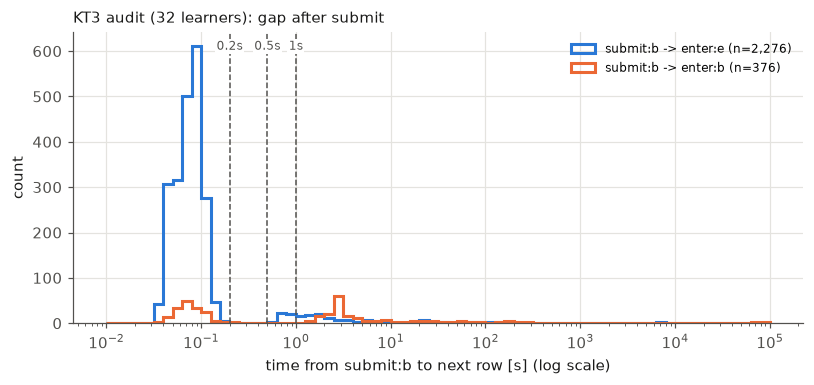

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.logspace(-2, 5, 71)
for t, color, label in [("enter:e", C1, "submit:b -> enter:e"), ("enter:b", C2, "submit:b -> enter:b")]:
    dt = gap_after_submit(kt3, t)
    ax.hist(dt.clip(lower=0.01), bins=bins, histtype="step", linewidth=2, color=color, label=f"{label} (n={len(dt):,})")
ax.set_xscale("log")
for x in AUTO_SEC_SENS:
    ax.axvline(x, color=MUTED, linestyle="--", linewidth=1)
    ax.text(x, ax.get_ylim()[1] * 0.97, f"{x:g}s", ha="center", va="top", fontsize=8, color=MUTED,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_xlabel("time from submit:b to next row [s] (log scale)")
ax.set_ylabel("count")
ax.set_title("KT3 audit (32 learners): gap after submit", loc="left", fontsize=10, color=INK)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**感度分析**：D1 の秒数だけを変え、D2〜D4 はそのまま。

In [9]:
rows = []
for name in ["KT4 監査32人（SEED=0）", "KT4 同じ32人"]:
    for sec in AUTO_SEC_SENS:
        dp, flow = extract_decision_points(DATA[name], auto_sec=sec)
        cnt = per_learner_counts(DATA[name], dp)
        sub = dp[dp["token"].eq("submit:b")]["action"].value_counts().reindex(ACTION_ORDER, fill_value=0)
        rows.append({"データ": name, "D1 秒数": sec, "D1 自動表示で除外": flow["D1 自動表示で除外"], "決定点": flow["決定点"],
                     **{f"submit後:{a}": int(v) for a, v in sub.items()},
                     f"{MIN_DP_PER_LEARNER}件以上の学習者": int((cnt >= MIN_DP_PER_LEARNER).sum())})
d1_sens = pd.DataFrame(rows).set_index(["データ", "D1 秒数"])
d1_sens

D1 自動表示で除外   決定点  submit後:次の問題  submit後:解説  submit後:講義  submit後:セッション終了  20件以上の学習者
データ               D1 秒数                                                                                    
KT4 監査32人（SEED=0） 0.2           728  1005            86          63           1                5          7
                  0.5           728  1005            86          63           1                5          7
                  1.0           749   984            86          42           1                5          7
KT4 同じ32人         0.2          2104  2802           164         167           1                9          5
                  0.5          2107  2799           164         164           1                9          5
                  1.0          2153  2753           164         118           1                9          5

**【事実】**
- KT3 監査32人の submit:b→enter:e は 2,276件。時間差の中央値は 0.078秒、≤0.2秒が 0.924、0.2〜0.5秒が 0.001、≤0.5秒が 0.926、≤1秒が 0.946。
- KT4 監査32人（SEED=0）の submit:b→enter:e は 795件。中央値 0.052秒、≤0.2秒 0.916、0.2〜0.5秒 0.000、≤0.5秒 0.916。
- submit:b→enter:b は、KT3 監査32人で 376件、中央値 1.954秒、≤0.2秒 0.431。KT4 監査32人（SEED=0）で 302件、中央値 1.516秒、≤0.2秒 0.480。
- KT4 同じ32人の時間差は、KT3 監査32人と同じ値。
- 感度分析（決定点の件数）
  - KT4 監査32人（SEED=0）：0.2秒で 1,005、0.5秒で 1,005、1秒で 984。
  - KT4 同じ32人：0.2秒で 2,802、0.5秒で 2,799、1秒で 2,753。
  - 変わるのは submit 後の「解説」の件数だけ。20件以上の学習者の人数（7人・5人）は、どの秒数でも同じ。

**【判断】**
- 0.2秒以内に解説が開くのは、人がボタンを押して開いたとは考えにくい。そのため、自動表示とみなす。
- 0.2〜0.5秒にはほとんど件数がない（分布の谷）。境界はその上の端の 0.5秒にした。
- 0.2秒・1秒にしても決定点の件数の変化は小さく、0.5秒の選び方に結果が大きく左右されることはない（上の感度分析の表）。

**【限界・推測】**
- 自動表示かどうかは、ログからは断定できない（推測）。アプリの仕様は確認していない。
- 0.5秒を超えて開いた解説が本当に学習者の選択かは、確かめていない。手動で開いたのか、表示が遅れただけなのかは区別できない。

## D2：diagnosis の行の扱い

> source が diagnosis の submit:b・quit:e は決定点にしない。行そのものは系列に残す。

In [10]:
def enter_e_rate(raw, by):
    s = raw[raw["token"].eq("submit:b")]
    t = s.groupby(by).agg(submit件数=("next_token", "size"), enter_e件数=("next_token", lambda x: int(x.eq("enter:e").sum())))
    t["enter_e率"] = t["enter_e件数"] / t["submit件数"]
    return t.sort_values("submit件数", ascending=False)

d2_source = {name: enter_e_rate(d, "source") for name, d in DATA.items()}
d2_platform = enter_e_rate(kt3, "platform")
display(d2_source["KT3 監査32人"].round(3))
display(d2_platform.round(3))

,submit件数,enter_e件数,enter_e率
source,,,
sprint,2405,2231,0.928
diagnosis,228,2,0.009
adaptive_offer,32,31,0.969
review_quiz,11,10,0.909
tutor,2,2,1.000


,submit件数,enter_e件数,enter_e率
platform,,,
mobile,2491,2154,0.865
web,187,122,0.652


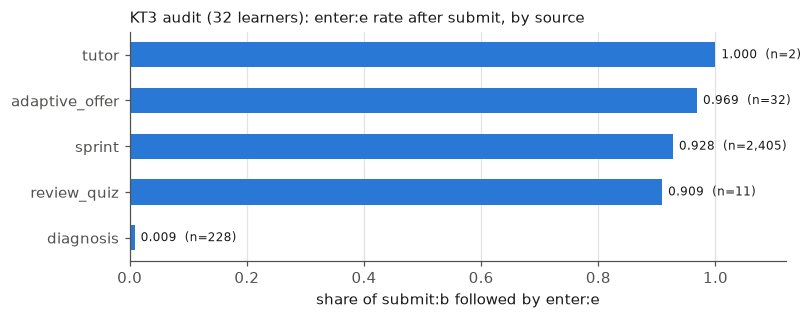

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.0))
t = d2_source["KT3 監査32人"].sort_values("enter_e率")
y = np.arange(len(t))
ax.barh(y, t["enter_e率"], height=0.55, color=C1)
ax.set_yticks(y, t.index)
ax.set_xlim(0, 1.12)
for yi, (r, n) in enumerate(zip(t["enter_e率"], t["submit件数"])):
    ax.text(r + 0.01, yi, f"{r:.3f}  (n={n:,})", va="center", fontsize=8, color=INK)
ax.set_xlabel("share of submit:b followed by enter:e")
ax.set_title("KT3 audit (32 learners): enter:e rate after submit, by source", loc="left", fontsize=10, color=INK)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [12]:
# 学習者単位：submit がすべて diagnosis の人と、D2 で除外される件数
s = kt3[kt3["token"].eq("submit:b")]
per_user = s.groupby("user_id").agg(submit=("token", "size"), diag_share=("source", lambda x: x.eq(DIAGNOSIS_SOURCE).mean()),
                                    enter_e_rate=("next_token", lambda x: x.eq("enter:e").mean()))
non_diag = s[s["source"].ne(DIAGNOSIS_SOURCE)]
d2_users = {"submit がすべて diagnosis の学習者": int(per_user["diag_share"].eq(1).sum()),
            "enter:e 率が 0 の学習者": int(per_user["enter_e_rate"].eq(0).sum()),
            "うち submit がすべて diagnosis": int((per_user["enter_e_rate"].eq(0) & per_user["diag_share"].eq(1)).sum()),
            "diagnosis 以外の submit がある学習者": int(non_diag["user_id"].nunique()),
            "diagnosis 以外の submit の enter:e 率": round(non_diag["next_token"].eq("enter:e").mean(), 3),
            "diagnosis 以外の submit 件数": len(non_diag)}
display(pd.Series(d2_users, name="KT3 監査32人").to_frame())
pd.DataFrame({name: {"D2 diagnosis で除外": flow["D2 diagnosis で除外"], "決定点": flow["決定点"]} for name, (_, flow) in DP.items()})

,KT3 監査32人
submit がすべて diagnosis の学習者,21.000
enter:e 率が 0 の学習者,20.000
うち submit がすべて diagnosis,20.000
diagnosis 以外の submit がある学習者,11.000
diagnosis 以外の submit の enter:e 率,0.928
diagnosis 以外の submit 件数,2450.000


,KT3 監査32人,KT4 同じ32人,KT4 監査32人（SEED=0）
D2 diagnosis で除外,228,228,233
決定点,2799,2799,1005


**【事実】**
- KT3 監査32人の submit:b の後に enter:e が来る割合（source 別）
  - sprint 0.928（2,405件）、diagnosis 0.009（228件）、adaptive_offer 0.969（32件）、review_quiz 0.909（11件）、tutor 1.000（2件）。
- platform 別：mobile 0.865（2,491件）、web 0.652（187件）。
- submit がすべて diagnosis の学習者は21人。enter:e 率が 0 の学習者20人は、全員この中に入る。
- diagnosis 以外の submit がある学習者は11人で、その 2,450件の enter:e 率は 0.928。
- D2 で除外される候補：KT3 監査32人と KT4 同じ32人で 228件、KT4 監査32人（SEED=0）で 233件。

**【判断】**
- diagnosis の submit の後はほとんど解説に進まない。次の行動を学習者が選んでいない（流れが固定されている）と考え、決定点から外す。
- 系列の文脈としては、行を残す。

**【限界・推測】**
- diagnosis が「最初の実力診断」で、解説が出ない作りだというのは推測。アプリの仕様は確認していない。
- diagnosis の中で、学習者が途中でやめる・飛ばすといった選択があり得るかは確かめていない。

## D3：quit:e の後に別の解説に入る行

> 「解説」に分類する。quit:e の後の選択肢は {次の問題, 解説, 講義, セッション終了}。

In [13]:
d3 = {}
for name, (dp, _) in DP.items():
    q = dp[dp["token"].eq("quit:e")]
    d3[name] = q["action"].value_counts().reindex(ACTION_ORDER + ["その他"], fill_value=0)
d3 = pd.DataFrame(d3).T
d3["合計"] = d3.sum(axis=1)
display(d3)
# 規則を決める前（報告の2節：D1・D2・D4 を外す）での quit:e→enter:e
dp_old, _ = extract_decision_points(kt3, auto_sec=None, exclude_diagnosis=False, drop_data_end=False)
q_old = dp_old[dp_old["token"].eq("quit:e")]
d3_old = {"quit:e": len(q_old), "quit:e→解説": int(q_old["action"].eq("解説").sum()),
          "その割合": round(q_old["action"].eq("解説").mean(), 3), "学習者数": int(q_old.loc[q_old["action"].eq("解説"), "user_id"].nunique())}
pd.Series(d3_old, name="KT3 監査32人（規則を決める前）").to_frame()

action,次の問題,解説,講義,セッション終了,その他,合計
KT3 監査32人,2123,155,10,173,0,2461
KT4 同じ32人,2123,155,10,173,0,2461
KT4 監査32人（SEED=0）,756,54,13,27,0,850


,KT3 監査32人（規則を決める前）
quit:e,2468.000
quit:e→解説,155.000
その割合,0.063
学習者数,5.000


**【事実】**
- D1〜D4 を当てはめた quit:e の後の行動（次の問題 / 解説 / 講義 / セッション終了）
  - KT4 同じ32人：2,123 / 155 / 10 / 173。
  - KT4 監査32人（SEED=0）：756 / 54 / 13 / 27。
  - どちらも「その他」は 0件。
- 規則を決める前（KT3 監査32人）：quit:e 2,468件のうち、直後が別の解説なのは 155件（0.063、5人）。

**【判断】**
- 解説を閉じた後に別の解説を開くのは、学習者が選んだ行動と考えられる。
- 「その他」として別に扱うと件数が少なく扱いにくいので、「解説」にまとめる。

**【限界・推測】**
- 別の解説が、学習者が選んだものか、アプリが続けて表示したもの（例：まとめて出題された問題の解説が順に開く）かは確かめていない。

## D4：観測の打ち切り（学習者の最後の行）

> 次の行がない決定点は除外する。60分を超える間隔で次の行が来る場合は「セッション終了」として残す。

In [14]:
d4 = {}
for name, (dp, flow) in DP.items():
    before = flow["決定点"] + flow["D4 データ末尾で除外"]
    d4[name] = {"除外前の候補": before, "D4 データ末尾で除外": flow["D4 データ末尾で除外"],
                "除外の割合": round(flow["D4 データ末尾で除外"] / before, 4),
                "残った決定点のうちセッション終了": int(dp["action"].eq(SESSION_END).sum()),
                "残った決定点に data_end が残っていない": bool(~dp["data_end"].any())}
pd.DataFrame(d4).T

,除外前の候補,D4 データ末尾で除外,除外の割合,残った決定点のうちセッション終了,残った決定点に data_end が残っていない
KT3 監査32人,2811,12,0.0043,182,True
KT4 同じ32人,2811,12,0.0043,182,True
KT4 監査32人（SEED=0）,1019,14,0.0137,32,True


In [15]:
# 規則を決める前（報告の2節）：セッション終了のうち、データ末尾によるもの（KT3 監査32人）
dp_old.groupby("token").agg(決定点=("action", "size"), セッション終了=("action", lambda x: int(x.eq(SESSION_END).sum())),
                            うちデータ末尾=("data_end", "sum"))

,決定点,セッション終了,うちデータ末尾
token,,,
quit:e,2468,180,7
submit:b,2678,38,25


**【事実】**
- 除外前の候補のうち、D4 で除外されるのは次の件数。
  - KT4 同じ32人：2,811件中 12件（0.0043）。
  - KT4 監査32人（SEED=0）：1,019件中 14件（0.0137）。
- 残った決定点に、データ末尾の行は残っていない。
- 規則を決める前（KT3 監査32人）
  - submit:b の後のセッション終了 38件のうち 25件、quit:e の後のセッション終了 180件のうち 7件が、データ末尾によるもの。

**【判断】**
- 学習者の最後の行の後は、本人が学習をやめたのか、データの収集期間が終わったのか分からない。
- それを「セッション終了」として数えると、終了の割合を過大に見積もるおそれがあるので除外する。除外は候補の約1%以下で、影響は小さい。

**【限界・推測】**
- 最後の行が本当に学習の終わりかどうかは、ログからは分からない。
- CLAUDE.md の未決定事項（セッション末尾を予測対象から外すか、「終了」を5クラス目にするか）は、この判断とは別で、まだ決めていない。

## D5：「ほぼ確定」の閾値

> 主は 0.95（ノートブックで事前に決めていた値）。この割合は記述統計としてだけ使い、決定点の定義には使わない。感度分析：0.90・0.99 を常に併記。

「ほぼ確定」の割合：トークン（`action_type:item_type`）単位の一次遷移で、次のトークンの最大確率 `max_p` が閾値以上の状態から出る遷移の割合（`phase1_ednet_audit*.ipynb` のセル13と同じ計算。カテゴリ定義が未決定なので全行を対象）。

In [16]:
def token_transition_stats(raw):
    tr = raw.dropna(subset=["next_token"])
    P = pd.crosstab(tr["token"], tr["next_token"], normalize="index")
    return pd.DataFrame({"n": tr["token"].value_counts(), "max_p": P.max(axis=1), "argmax_next": P.idxmax(axis=1)}).sort_values("n", ascending=False)

def near_deterministic_share(stats, th):
    return stats.loc[stats["max_p"] >= th, "n"].sum() / stats["n"].sum()

TS = {name: token_transition_stats(d) for name, d in DATA.items()}
d5 = pd.DataFrame({name: {f"≥{th:.2f}": near_deterministic_share(st, th) for th in DET_THRESHOLD_SENS} for name, st in TS.items()}).T
d5["max_p が 0.95〜0.99 のトークン数"] = [int(st["max_p"].between(0.95, 0.99, inclusive="left").sum()) for st in TS.values()]
d5["決定点（閾値を使わない）"] = [flow["決定点"] for _, flow in DP.values()]
d5.round(3)

,≥0.90,≥0.95,≥0.99,max_p が 0.95〜0.99 のトークン数,決定点（閾値を使わない）
KT3 監査32人,0.542,0.177,0.177,0,2799
KT4 同じ32人,0.098,0.002,0.002,0,2799
KT4 監査32人（SEED=0）,0.280,0.018,0.018,0,1005


In [17]:
# 閾値 0.90 と 0.95 の間に max_p があるトークン
pd.concat({name: st[(st["max_p"] >= 0.90) & (st["max_p"] < 0.95)] for name, st in TS.items()}).round(3)

n  max_p argmax_next
                  token                           
KT3 監査32人         enter:b  2678  0.917   respond:q
                  quit:e   2461  0.918     enter:b
KT4 同じ32人         quit:e   2461  0.918     enter:b
KT4 監査32人（SEED=0） enter:e   855  0.935      quit:e
                  quit:e    850  0.915     enter:b

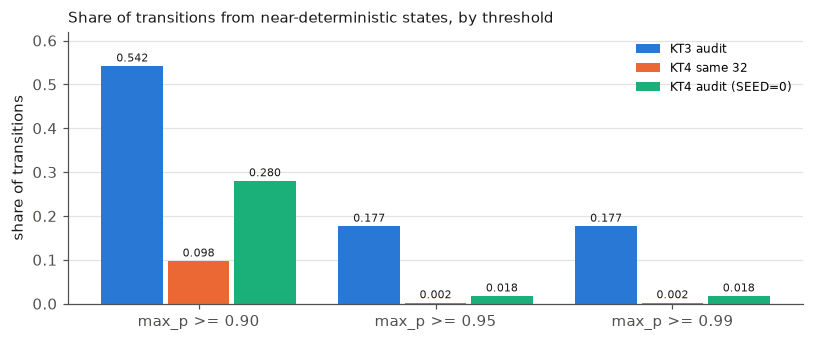

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
names = list(TS)
x = np.arange(len(DET_THRESHOLD_SENS))
w = 0.26
for i, (name, color, label) in enumerate(zip(names, [C1, C2, C3], ["KT3 audit", "KT4 same 32", "KT4 audit (SEED=0)"])):
    vals = [near_deterministic_share(TS[name], th) for th in DET_THRESHOLD_SENS]
    bars = ax.bar(x + (i - 1) * (w + 0.02), vals, width=w, color=color, label=label)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=7, color=INK)
ax.set_xticks(x, [f"max_p >= {th:.2f}" for th in DET_THRESHOLD_SENS])
ax.set_ylabel("share of transitions")
ax.set_ylim(0, 0.62)
ax.set_title("Share of transitions from near-deterministic states, by threshold", loc="left", fontsize=10, color=INK)
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**【事実】**
- 「ほぼ確定」の割合（閾値 0.90 / 0.95 / 0.99）
  - KT3 監査32人：0.542 / 0.177 / 0.177。
  - KT4 同じ32人：0.098 / 0.002 / 0.002。
  - KT4 監査32人（SEED=0）：0.280 / 0.018 / 0.018。
- max_p が 0.95〜0.99 のトークンは、どのデータにもない（0個）。
- max_p が 0.90〜0.95 のトークン
  - KT3 監査32人：enter:b（0.917）、quit:e（0.918）。
  - KT4 同じ32人：quit:e（0.918）。
  - KT4 監査32人（SEED=0）：enter:e（0.935）、quit:e（0.915）。
- 決定点の件数（2,799 / 2,799 / 1,005）は、閾値を使わずに決まる。

**【判断】**
- 監査データを見てから閾値を選ぶと、結果に合わせた選び方になる。そのため、事前に決めていた 0.95 を主にし、0.90・0.99 を常に併記する。
- 決定点は D1〜D4 の規則で決めていて、閾値を使わない。そのため、閾値の選び方は決定点に影響しない（上の表の「決定点」列）。

**【限界・推測】**
- 「ほぼ確定」の割合は、閾値の近く（0.90〜0.95）にある少数のトークンで大きく変わる。この割合の値そのものを強く解釈しない。

## D6：同一時刻の行の並べ方

> 元ファイルの順を保つ（`user_id`→`timestamp` の安定ソート）。全行の遷移では、同一時刻の遷移の割合を併記する。

In [19]:
def same_ts_pairs(raw):
    tr = raw.dropna(subset=["next_token"])
    same = tr[tr["next_ts"].eq(tr["timestamp"])]
    return (same["token"] + " → " + same["next_token"]).value_counts()

d6 = {}
for name, d in DATA.items():
    tr = d.dropna(subset=["next_token"])
    dp, _ = DP[name]
    d6[name] = {"遷移": len(tr), "同一時刻の遷移": int(tr["next_ts"].eq(tr["timestamp"]).sum()),
                "同一時刻の遷移の割合": round(tr["next_ts"].eq(tr["timestamp"]).mean(), 3),
                "決定点": len(dp), "次の行と同一時刻の決定点": int(dp["next_ts"].eq(dp["timestamp"]).sum())}
display(pd.DataFrame(d6).T)
# 同一時刻の組の上位（KT4 同じ32人）
same_ts_pairs(kt4_same).head(6).rename("件数").to_frame()

,遷移,同一時刻の遷移,同一時刻の遷移の割合,決定点,次の行と同一時刻の決定点
KT3 監査32人,14070.0,13.0,0.001,2799.0,0.0
KT4 同じ32人,25843.0,2471.0,0.096,2799.0,0.0
KT4 監査32人（SEED=0）,6492.0,92.0,0.014,1005.0,0.0


,件数
pause_audio:b → play_audio:b,1747
play_audio:b → pause_audio:b,502
pause_audio:b → submit:b,59
play_audio:b → play_audio:b,46
pause_audio:b → pause_audio:b,42
pause_audio:b → quit:e,32


In [20]:
# pause_audio と play_audio が同一時刻のとき、ファイル内の順が一定でないこと
pd.DataFrame({name: same_ts_pairs(d).reindex(["play_audio:b → pause_audio:b", "pause_audio:b → play_audio:b"], fill_value=0)
              for name, d in DATA.items() if name != "KT3 監査32人"})

,KT4 同じ32人,KT4 監査32人（SEED=0）
play_audio:b → pause_audio:b,502,5
pause_audio:b → play_audio:b,1747,13


**【事実】**
- 次の行と同一時刻の遷移の割合：KT3 監査32人 0.001（13件）、KT4 同じ32人 0.096（2,471件）、KT4 監査32人（SEED=0）0.014（92件）。
- 次の行と同一時刻の決定点は、3つのデータとも 0件。
- KT4 同じ32人で同一時刻の組の上位
  - pause_audio:b → play_audio:b 1,747件
  - play_audio:b → pause_audio:b 502件
  - pause_audio:b → submit:b 59件
- KT4 監査32人（SEED=0）での同じ2つの組は、13件と5件。

**【判断】**
- 同一時刻の行をどう並べるべきかの情報がログにないので、元ファイルの順を保つ。
- 決定点の次の行が同一時刻になる例はないので、決定点の集計には影響しない。全行の遷移を数えるときは、同一時刻の遷移の割合を限界として併記する。

**【限界・推測】**
- 元ファイルの順が、実際に操作した順かどうかは確かめていない。
- 本番データで、決定点の次の行が同一時刻になる例があるかどうかは分からない。本番の前処理でも、その件数を数えて記録する。

## D7：決定点で評価する学習者の条件（ユーザーが決定）

> 決定点の評価には、決定点（D1〜D4 で残ったもの）が合計 **20件以上** の学習者だけを含める。

In [21]:
COUNTS = {name: per_learner_counts(DATA[name], dp) for name, (dp, _) in DP.items()}
d7 = {}
for name, cnt in COUNTS.items():
    ok = cnt[cnt >= MIN_DP_PER_LEARNER]
    d7[name] = {"学習者": len(cnt), "0件": int(cnt.eq(0).sum()), "1〜9件": int(cnt.between(1, 9).sum()),
                "10〜19件": int(cnt.between(10, 19).sum()), f"{MIN_DP_PER_LEARNER}件以上": len(ok),
                "対象になる決定点": int(ok.sum()), "決定点の合計": int(cnt.sum()),
                "対象の割合": round(ok.sum() / cnt.sum(), 3), "20件以上の人の件数": ", ".join(map(str, sorted(ok.tolist())))}
pd.DataFrame(d7).T

,学習者,0件,1〜9件,10〜19件,20件以上,対象になる決定点,決定点の合計,対象の割合,20件以上の人の件数
KT3 監査32人,32,21,6,0,5,2772,2799,0.99,"47, 106, 144, 1084, 1391"
KT4 同じ32人,32,21,6,0,5,2772,2799,0.99,"47, 106, 144, 1084, 1391"
KT4 監査32人（SEED=0）,32,18,4,3,7,943,1005,0.938,"39, 42, 47, 96, 147, 256, 316"


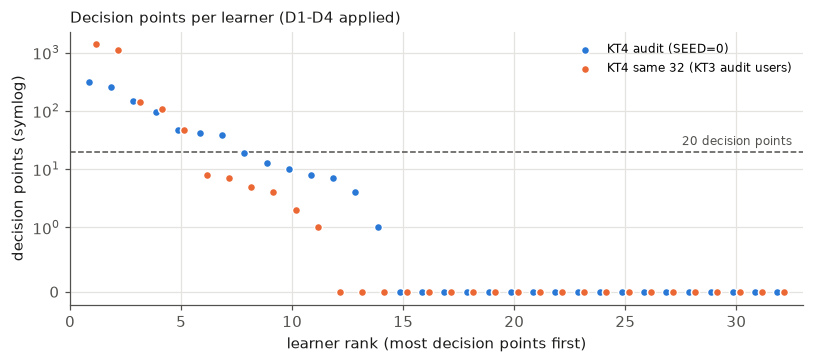

In [22]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for name, color, label, off in [("KT4 監査32人（SEED=0）", C1, "KT4 audit (SEED=0)", -0.15), ("KT4 同じ32人", C2, "KT4 same 32 (KT3 audit users)", 0.15)]:
    c = np.sort(COUNTS[name].to_numpy())[::-1]
    ax.scatter(np.arange(1, len(c) + 1) + off, c, s=28, color=color, edgecolor="white", linewidth=1, label=label, zorder=3)
ax.set_yscale("symlog", linthresh=1)
ax.axhline(MIN_DP_PER_LEARNER, color=MUTED, linestyle="--", linewidth=1)
ax.text(32.5, MIN_DP_PER_LEARNER * 1.15, f"{MIN_DP_PER_LEARNER} decision points", ha="right", va="bottom", fontsize=8, color=MUTED)
ax.set_xlabel("learner rank (most decision points first)")
ax.set_ylabel("decision points (symlog)")
ax.set_xlim(0, 33)
ax.set_title("Decision points per learner (D1-D4 applied)", loc="left", fontsize=10, color=INK)
ax.legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

**【事実】**
- 学習者ごとの決定点の件数（0件 / 1〜9件 / 10〜19件 / 20件以上）
  - KT4 同じ32人：21 / 6 / 0 / 5人。
  - KT4 監査32人（SEED=0）：18 / 4 / 3 / 7人。
- 20件以上の学習者が持つ決定点
  - KT4 同じ32人：2,799件中 2,772件（0.990）。件数は 47、106、144、1,084、1,391。
  - KT4 監査32人（SEED=0）：1,005件中 943件（0.938）。件数は 39、42、47、96、147、256、316。

**【判断】**（ユーザーの決定。根拠は報告の記録）
- 学習者ごとに時系列を前半/後半に分けて評価するので、決定点が少ない学習者は評価できない。
- 20件は、前半・後半それぞれ約10件を想定した値。

**【限界・推測】**
- 評価できる学習者は、監査サンプルでは32人中5〜7人に限られる。本番データでも一部の学習者だけになると見込まれる（推測）。
- 決定点の評価は「アプリをよく使う学習者」についての結果になる。その範囲を超えて一般化しない。
- 20件という値そのものの妥当性（10件で前半・後半の推定が安定するか）は確かめていない。

## 検証：報告書の数値との照合

`reports/phase1_decision_points.md`（DP）と `reports/phase1_decisions.md`（DEC）に書いた主要な数値を、このノートブックの出力と照合する。
報告書で丸めて書いた値は、同じ桁に丸めて比べる。

In [23]:
def r(x, nd=3):
    return round(float(x), nd)

g_e = gap_summary(gap_after_submit(kt3, "enter:e"))
g_b = gap_summary(gap_after_submit(kt3, "enter:b"))
g_e4 = {name: gap_summary(gap_after_submit(DATA[name], "enter:e")) for name in ["KT4 監査32人（SEED=0）", "KT4 同じ32人"]}
src3 = d2_source["KT3 監査32人"]["enter_e率"]
s_old = dp_old[dp_old["token"].eq("submit:b")]
dpc_old = dp_old.groupby(["user_id", "token"]).size().unstack(fill_value=0).reindex(KT3_USERS, fill_value=0)
dpc_old["合計"] = dpc_old.sum(axis=1)
flow = {name: f for name, (_, f) in DP.items()}
act = {name: dp.groupby(["token", "action"]).size() for name, (dp, _) in DP.items()}
SEEDN, SAME = "KT4 監査32人（SEED=0）", "KT4 同じ32人"

checks = [
    # (出典, 項目, 報告書の値, ノートブックの値)
    ("DP 1節", "KT3 submit:b 件数", 2678, flow["KT3 監査32人"]["submit:b"]),
    ("DP 1節", "KT3 submit:b→enter:e 件数", 2276, g_e["件数"]),
    ("DP 1節", "KT3 submit:b→enter:e 時間差の中央値(秒)", 0.078, r(g_e["中央値(秒)"])),
    ("DP 1節", "KT3 submit:b→enter:e 0〜1秒の割合", 0.946, r(g_e["≤1秒"])),
    ("DP 1節", "KT3 submit:b→enter:b 件数", 376, g_b["件数"]),
    ("DP 1節", "KT3 submit:b→enter:b 時間差の中央値(秒)", 1.954, r(g_b["中央値(秒)"])),
    ("DP 1節", "KT3 submit:b→enter:b 0〜1秒の割合", 0.447, r(g_b["≤1秒"])),
    ("DP 1節", "enter:e 率 sprint", 0.928, r(src3["sprint"])),
    ("DP 1節", "enter:e 率 diagnosis", 0.009, r(src3["diagnosis"])),
    ("DP 1節", "enter:e 率 adaptive_offer", 0.969, r(src3["adaptive_offer"])),
    ("DP 1節", "enter:e 率 mobile", 0.865, r(d2_platform.loc["mobile", "enter_e率"])),
    ("DP 1節", "enter:e 率 web", 0.652, r(d2_platform.loc["web", "enter_e率"])),
    ("DP 1節", "enter:e 率 0 の学習者", 20, d2_users["enter:e 率が 0 の学習者"]),
    ("DP 1節", "submit がすべて diagnosis の学習者", 21, d2_users["submit がすべて diagnosis の学習者"]),
    ("DP 1節", "diagnosis 以外の submit の enter:e 率", 0.928, d2_users["diagnosis 以外の submit の enter:e 率"]),
    ("DP 2節", "submit:b 後 解説（規則前）", 2272, int(s_old["action"].eq("解説").sum())),
    ("DP 2節", "submit:b 後 次の問題（規則前）", 367, int(s_old["action"].eq("次の問題").sum())),
    ("DP 2節", "submit:b 後 セッション終了（規則前）", 38, int(s_old["action"].eq(SESSION_END).sum())),
    ("DP 2節", "submit:b 後 データ末尾（規則前）", 25, int(s_old["data_end"].sum())),
    ("DP 2節", "quit:e 後 次の問題（規則前）", 2123, int(q_old["action"].eq("次の問題").sum())),
    ("DP 2節", "quit:e 後 セッション終了（規則前）", 180, int(q_old["action"].eq(SESSION_END).sum())),
    ("DP 2節", "quit:e 後 別の解説（規則前）", 155, d3_old["quit:e→解説"]),
    ("DP 2節", "quit:e 後 データ末尾（規則前）", 7, int(q_old["data_end"].sum())),
    ("DP 2節", "決定点（規則前）合計の最大", 2445, int(dpc_old["合計"].max())),
    ("DP 2節", "決定点（規則前）1〜10件の学習者", 21, int(dpc_old["合計"].between(1, 10).sum())),
    ("DP 3節", "KT4 同じ32人 行数", 25875, len(kt4_same)),
    ("DP 3節", "KT4 同じ32人 同一時刻の遷移の割合", 0.096, d6[SAME]["同一時刻の遷移の割合"]),
    ("DP 4節", "ほぼ確定 KT3 ≥0.90", 0.542, r(d5.loc["KT3 監査32人", "≥0.90"])),
    ("DP 4節", "ほぼ確定 KT3 ≥0.95", 0.177, r(d5.loc["KT3 監査32人", "≥0.95"])),
    ("DP 4節", "ほぼ確定 KT3 ≥0.99", 0.177, r(d5.loc["KT3 監査32人", "≥0.99"])),
    ("DP 4節", "ほぼ確定 KT4 同じ32人 ≥0.90", 0.098, r(d5.loc[SAME, "≥0.90"])),
    ("DP 4節", "ほぼ確定 KT4 同じ32人 ≥0.95", 0.002, r(d5.loc[SAME, "≥0.95"])),
    ("DP 4節", "ほぼ確定 KT4 SEED ≥0.90", 0.280, r(d5.loc[SEEDN, "≥0.90"])),
    ("DP 4節", "ほぼ確定 KT4 SEED ≥0.95", 0.018, r(d5.loc[SEEDN, "≥0.95"])),
    ("DEC D1", "KT4 SEED submit:b→enter:e ≤0.2秒（約92%）", 0.92, r(g_e4[SEEDN]["≤0.2秒"], 2)),
    ("DEC D1", "KT4 同じ32人 submit:b→enter:e ≤0.2秒（約92%）", 0.92, r(g_e4[SAME]["≤0.2秒"], 2)),
    ("DEC D3", "quit:e 後に別の解説の割合（約6%）", 0.06, r(d3_old["その割合"], 2)),
    ("DEC D6", "KT4 SEED 同一時刻の遷移の割合（1.4%）", 0.014, d6[SEEDN]["同一時刻の遷移の割合"]),
    ("DEC D6", "次の行と同一時刻の決定点 SEED", 0, d6[SEEDN]["次の行と同一時刻の決定点"]),
    ("DEC D6", "次の行と同一時刻の決定点 同じ32人", 0, d6[SAME]["次の行と同一時刻の決定点"]),
]
for name, exp in [(SEEDN, dict(sub=1125, auto=728, quit=855, diag=233, end=14, dp=1005, q=(756, 54, 13, 27), s=(86, 63, 1, 5), z=18, low=4, hi=10, ok=7, cov=943, mid=3)),
                  (SAME, dict(sub=2678, auto=2107, quit=2468, diag=228, end=12, dp=2799, q=(2123, 155, 10, 173), s=(164, 164, 1, 9), z=21, low=6, hi=5, ok=5, cov=2772, mid=0))]:
    f, a, c = flow[name], act[name], COUNTS[name]
    checks += [("DEC 表", f"{name} submit:b", exp["sub"], f["submit:b"]),
               ("DEC 表", f"{name} D1 自動表示で除外", exp["auto"], f["D1 自動表示で除外"]),
               ("DEC 表", f"{name} quit:e", exp["quit"], f["quit:e"]),
               ("DEC 表", f"{name} D2 diagnosis で除外", exp["diag"], f["D2 diagnosis で除外"]),
               ("DEC 表", f"{name} D4 データ末尾で除外", exp["end"], f["D4 データ末尾で除外"]),
               ("DEC 表", f"{name} 決定点", exp["dp"], f["決定点"]),
               ("DEC 表", f"{name} quit:e 後 次の問題/解説/講義/終了", exp["q"], tuple(int(a.get(("quit:e", k), 0)) for k in ACTION_ORDER[:2] + ["講義", SESSION_END])),
               ("DEC 表", f"{name} submit:b 後 次の問題/解説/講義/終了", exp["s"], tuple(int(a.get(("submit:b", k), 0)) for k in ACTION_ORDER[:2] + ["講義", SESSION_END])),
               ("DEC 表", f"{name} 決定点0件の学習者", exp["z"], int(c.eq(0).sum())),
               ("DEC 表", f"{name} 決定点1〜9件の学習者", exp["low"], int(c.between(1, 9).sum())),
               ("DEC 表", f"{name} 決定点10件以上の学習者", exp["hi"], int(c.ge(10).sum())),
               ("DEC D7", f"{name} 20件以上の学習者", exp["ok"], d7[name][f"{MIN_DP_PER_LEARNER}件以上"]),
               ("DEC D7", f"{name} 対象になる決定点", exp["cov"], d7[name]["対象になる決定点"]),
               ("DEC D7", f"{name} 10〜19件の学習者", exp["mid"], d7[name]["10〜19件"])]

result = pd.DataFrame(checks, columns=["出典", "項目", "報告書", "ノートブック"])
result["一致"] = [str(a) == str(b) for a, b in zip(result["報告書"], result["ノートブック"])]
print(f"照合 {len(result)} 項目 / 一致 {int(result['一致'].sum())} / 不一致 {int((~result['一致']).sum())}")
display(result[~result["一致"]] if (~result["一致"]).any() else "不一致なし")
assert result["一致"].all(), "報告書と一致しない数値がある（上の表）"

照合 68 項目 / 一致 68 / 不一致 0


'不一致なし'